In [2]:
import seaborn as sns
from sklearn.datasets import make_blobs

In [3]:
# the create of data 
X,y = make_blobs(
    n_samples = 1000,
    n_features = 2,
    centers = 4,
    random_state = 42
)

<Axes: >

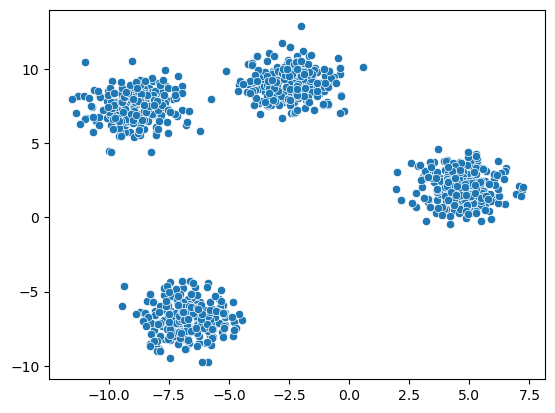

In [6]:
# Visualize
sns.scatterplot(x = X[:,0],y = X[:,1])

In [7]:
# the k-mean_clustering
from sklearn.cluster import KMeans

In [8]:
k = 4
kmeans = KMeans(
    n_clusters = k,
    random_state = 42
)
    

In [10]:
labels = kmeans.fit_predict(X)
# labels = cluster number

<Axes: >

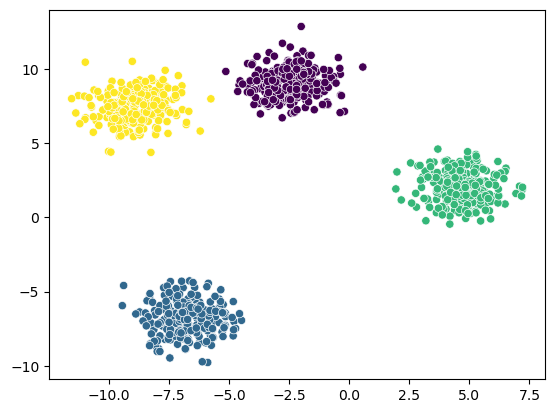

In [11]:
sns.scatterplot(x = X[:,0],y=X[:,1],c=labels)

### Choose our K value - elbow; silhouette score

In [15]:
# Elbow method 

WCSS =[]
for k in range(1,21):
    kmeans = KMeans(n_clusters = k)
    kmeans.fit_predict(X)
    WCSS.append(kmeans.inertia_)

<Axes: >

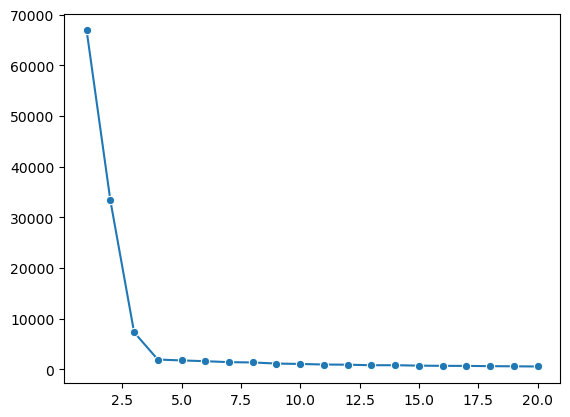

In [16]:
sns.lineplot(x = range(1,21),y = WCSS , marker = 'o')

In [17]:
# authomatic way - kneed Module
!pip install kneed

In [18]:
from kneed import KneeLocator 

In [23]:
knee = KneeLocator(range(1,21),WCSS,curve="convex",direction = "decreasing")

In [24]:
print("Optimal k value",knee.elbow)

Optimal k value 4


## Silhouette Score


In [25]:
from sklearn.metrics import silhouette_score

In [28]:
ss = []
for k in range(2,21):
    kmeans = KMeans(n_clusters = k)
    labels = kmeans.fit_predict(X)
    score  = silhouette_score(X,labels)
    ss.append(score)
    

<Axes: >

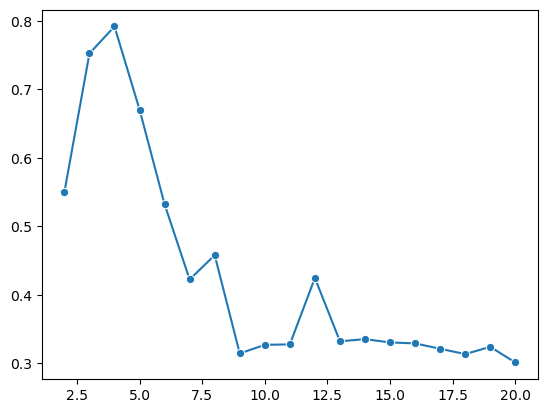

In [30]:
# plot -k & ss

sns.lineplot(x = range(2,21),y = ss, marker = "o")